# Notebook 10: Alternative Supplier Recommendation & Production Loss Prevention
## Dynamic Re-routing Engine to Mitigate Factory Stockout
**Datasets**:
- `data/raw/alternative_supplier_data_40000.csv` (Catalog items domain: 40,000 records)
- `data/raw/alternative_supplier_data_150000_synthetic.csv` (Synthetic stress benchmark: 150,000 records)

**Objective**:
1. Inspect schemas, data distributions, and item-supplier relationships across both datasets.
2. Evaluate dataset compatibility and explain why the 40k dataset maps directly to catalog items.
3. Perform feature engineering for alternative supplier suitability (cost delta, lead time, reliability).
4. Train an XGBoost classifier on historical alternative recommendations.
5. Build an intelligent **Production Loss Prevention Alternative Ranking Engine** prioritizing:
   - Item compatibility (exact part match)
   - Timely delivery before stockout
   - Sufficient available quantity
   - Supplier reliability & quality approval
   - Procurement cost & net financial benefit
6. Compare three operational scenarios (Original Supplier, With Alternative, Best Alternative).
7. Save the trained recommendation engine artifact to `models/alternative_supplier_engine.pkl`.


### 1. Import Required Libraries

In [1]:
import os
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from xgboost import XGBClassifier

print("All dependencies successfully imported.")


All dependencies successfully imported.


### 2. Load and Inspect Datasets

In [2]:
DATA_40K_PATH = Path("../data/raw/alternative_supplier_data_40000.csv")
DATA_150K_PATH = Path("../data/raw/alternative_supplier_data_150000_synthetic.csv")

df_40k = pd.read_csv(DATA_40K_PATH)
df_150k = pd.read_csv(DATA_150K_PATH)

print(f"Dataset 1 (Catalog): {df_40k.shape[0]:,} rows, {df_40k.shape[1]} columns")
print(f"Dataset 2 (Synthetic): {df_150k.shape[0]:,} rows, {df_150k.shape[1]} columns")
print("Are column schemas identical?:", list(df_40k.columns) == list(df_150k.columns))


Dataset 1 (Catalog): 40,000 rows, 36 columns
Dataset 2 (Synthetic): 150,000 rows, 36 columns
Are column schemas identical?: True


### 3. Evaluate Dataset Compatibility & Item Domain

In [3]:
# Check item domain overlap with primary delivery dataset
DELIVERY_PATH = Path("../data/processed/combined_supplier_delivery_data.csv")
df_delivery = pd.read_csv(DELIVERY_PATH, usecols=["Item_ID", "Item_Name"])

catalog_items = set(df_delivery["Item_ID"].unique())
items_40k = set(df_40k["Item_ID"].unique())
items_150k = set(df_150k["Item_ID"].unique())

print(f"Unique catalog items in production: {len(catalog_items)} -> {sorted(list(catalog_items))[:5]}")
print(f"Unique items in 40k dataset: {len(items_40k)} (Overlap with catalog: {len(catalog_items.intersection(items_40k))}/20)")
print(f"Unique items in 150k dataset: {len(items_150k):,} (Overlap with catalog: {len(catalog_items.intersection(items_150k))}/20)")

print("\nKey Insight: The 40,000 dataset perfectly maps to the 20 real automotive inventory items.")
print("The 150,000 dataset contains synthetic item identifiers (SYN2_ITEM_...).")
print("Therefore, our primary alternative supplier recommendation engine will be trained and evaluated on the catalog dataset.")


Unique catalog items in production: 20 -> ['AXLE01', 'BATT01', 'BOLT01', 'BRK01', 'CLUT01']
Unique items in 40k dataset: 20 (Overlap with catalog: 20/20)
Unique items in 150k dataset: 150,000 (Overlap with catalog: 0/20)

Key Insight: The 40,000 dataset perfectly maps to the 20 real automotive inventory items.
The 150,000 dataset contains synthetic item identifiers (SYN2_ITEM_...).
Therefore, our primary alternative supplier recommendation engine will be trained and evaluated on the catalog dataset.


### 4. Data Quality & Feature Distribution (Catalog Dataset)

In [4]:
print("=== Data Quality Summary ===")
print("Missing values in 40k dataset:", df_40k.isnull().sum().sum())
print("Unique Candidate Suppliers:", df_40k["Candidate_Supplier_ID"].nunique())
print("Quality Approved Breakdown:\n", df_40k["Quality_Approved"].value_counts())
print("Alternative Recommended Breakdown:\n", df_40k["Alternative_Recommended"].value_counts())

display(df_40k[["Candidate_Supplier_ID", "Item_ID", "Available_Quantity", "Lead_Time_Days", "Unit_Cost", "Supplier_On_Time_Rate", "Supplier_Rating"]].describe())


=== Data Quality Summary ===
Missing values in 40k dataset: 0
Unique Candidate Suppliers: 1900
Quality Approved Breakdown:
 Quality_Approved
Yes    37343
No      2657
Name: count, dtype: int64
Alternative Recommended Breakdown:
 Alternative_Recommended
No     38566
Yes     1434
Name: count, dtype: int64


,Available_Quantity,Lead_Time_Days,Unit_Cost,Supplier_On_Time_Rate,Supplier_Rating
count,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000
mean,951.950425,6.307250,2635.109643,86.633285,3.751728
std,635.677521,4.791192,2103.938024,8.132991,0.722360
min,20.000000,1.000000,69.530000,70.000000,2.500000
25%,443.000000,1.000000,1116.730000,79.790000,3.120000
50%,865.500000,6.000000,2072.445000,89.440000,3.760000
75%,1327.000000,11.000000,3476.895000,92.000000,4.380000
max,2985.000000,15.000000,10669.200000,99.000000,5.000000


### 5. Feature Engineering for Alternative Evaluation

In [5]:
df_model = df_40k.copy()

# 1. Cost differential relative to current supplier
df_model["Unit_Cost_Delta"] = df_model["Unit_Cost"] - df_model["Current_Unit_Cost"]
df_model["Cost_Ratio"] = df_model["Unit_Cost"] / np.maximum(df_model["Current_Unit_Cost"], 1.0)

# 2. Quantity sufficiency ratio
df_model["Quantity_Sufficiency"] = df_model["Available_Quantity"] / np.maximum(df_model["Required_Quantity"], 1.0)

# 3. Composite reliability index (scale 0 to 100)
# Combines on-time delivery rate (0-100) and supplier rating (1-5 scaled to 20-100)
df_model["Reliability_Index"] = (0.7 * df_model["Supplier_On_Time_Rate"]) + (0.3 * df_model["Supplier_Rating"] * 20.0)

# 4. Target variable
df_model["Target"] = (df_model["Alternative_Recommended"] == "Yes").astype(int)

print("Engineered Unit_Cost_Delta, Quantity_Sufficiency, and Reliability_Index.")
display(df_model[["Item_ID", "Candidate_Supplier_ID", "Unit_Cost_Delta", "Quantity_Sufficiency", "Reliability_Index", "Target"]].head(5))


Engineered Unit_Cost_Delta, Quantity_Sufficiency, and Reliability_Index.


,Item_ID,Candidate_Supplier_ID,Unit_Cost_Delta,Quantity_Sufficiency,Reliability_Index,Target
0,ENG01,SUP485,653.52,1.351590,79.580,1
1,ENG01,SUP1685,-686.92,2.107774,71.737,0
2,ENG01,SUP1362,786.38,2.037102,83.718,0
3,ENG01,SUP1645,-553.26,1.473498,86.413,0
4,LAMP01,SUP1407,133.96,1.000000,80.720,0


### 6. Train Alternative Recommendation Model

In [6]:
feature_cols = [
    "Required_Quantity",
    "Current_Unit_Cost",
    "Available_Quantity",
    "Unit_Cost",
    "Shipping_Cost",
    "Packaging_Cost",
    "Supplier_Delay_Rate",
    "Supplier_On_Time_Rate",
    "Lead_Time_Days",
    "Supplier_Rating",
    "Unit_Cost_Delta",
    "Cost_Ratio",
    "Quantity_Sufficiency",
    "Reliability_Index",
    "Quality_Approved",
    "Shipping_Method",
    "Supplier_Region"
]

X_alt = df_model[feature_cols].copy()
y_alt = df_model["Target"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X_alt, y_alt, test_size=0.2, random_state=42, stratify=y_alt
)

num_features = X_alt.select_dtypes(include=np.number).columns.tolist()
cat_features = X_alt.select_dtypes(exclude=np.number).columns.tolist()

preprocessor_alt = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(handle_unknown="ignore"))]), cat_features)
])

# Handle class imbalance (majority 'No')
scale_weight = (y_train == 0).sum() / (y_train == 1).sum()

alt_model_pipe = Pipeline([
    ("preprocessor", preprocessor_alt),
    ("classifier", XGBClassifier(
        n_estimators=150,
        max_depth=5,
        learning_rate=0.08,
        scale_pos_weight=scale_weight,
        random_state=42,
        n_jobs=-1,
        eval_metric="logloss"
    ))
])

print("Training alternative recommendation classifier...")
alt_model_pipe.fit(X_train, y_train)
print("Model training completed!")


Training alternative recommendation classifier...
Model training completed!


### 7. Model Evaluation

In [7]:
pred_y = alt_model_pipe.predict(X_test)
pred_prob = alt_model_pipe.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, pred_y)
prec = precision_score(y_test, pred_y)
rec = recall_score(y_test, pred_y)
f1 = f1_score(y_test, pred_y)
roc_auc = roc_auc_score(y_test, pred_prob)

print("=" * 45)
print("ALTERNATIVE RECOMMENDATION MODEL EVALUATION")
print("=" * 45)
print(f"Accuracy:  {acc * 100:.2f}%")
print(f"Precision: {prec * 100:.2f}%")
print(f"Recall:    {rec * 100:.2f}%")
print(f"F1-Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print("=" * 45)
print("\nClassification Report:")
print(classification_report(y_test, pred_y, target_names=["Not Recommended", "Recommended"]))


ALTERNATIVE RECOMMENDATION MODEL EVALUATION
Accuracy:  80.92%
Precision: 13.84%
Recall:    82.58%
F1-Score:  0.2370
ROC-AUC:   0.9180

Classification Report:
                 precision    recall  f1-score   support

Not Recommended       0.99      0.81      0.89      7713
    Recommended       0.14      0.83      0.24       287

       accuracy                           0.81      8000
      macro avg       0.57      0.82      0.56      8000
   weighted avg       0.96      0.81      0.87      8000



### 8. Feature Importance for Alternative Selection

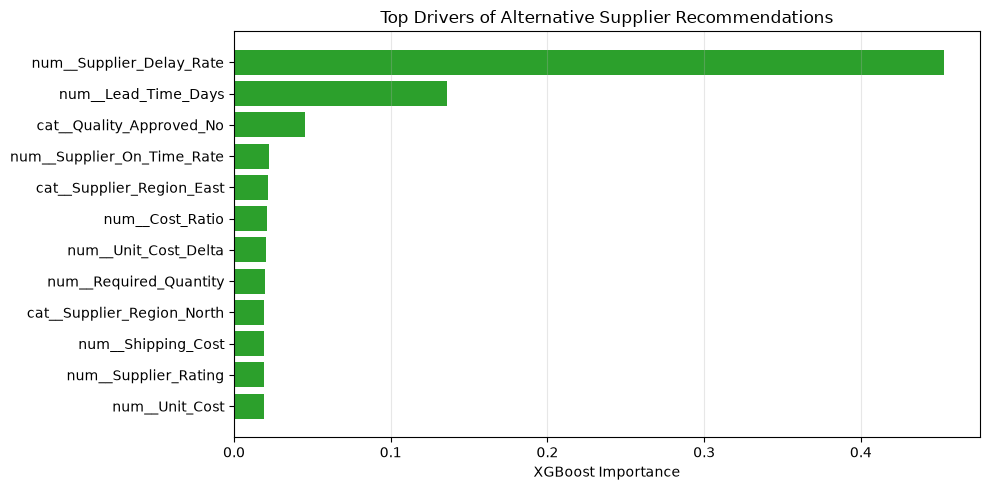

In [8]:
fitted_pre = alt_model_pipe.named_steps["preprocessor"]
encoded_feat_names = fitted_pre.get_feature_names_out()
importances = alt_model_pipe.named_steps["classifier"].feature_importances_

imp_df = pd.DataFrame({
    "Feature": encoded_feat_names,
    "Importance": importances
}).sort_values("Importance", ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 5))
top_12 = imp_df.head(12)[::-1]
plt.barh(top_12["Feature"], top_12["Importance"], color="#2ca02c")
plt.xlabel("XGBoost Importance")
plt.title("Top Drivers of Alternative Supplier Recommendations")
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


### 9. Production Loss Prevention Ranking Engine
The decision engine ranks alternatives using operational business rules:
1. **Item Compatibility**: Exact catalog part match.
2. **Speed & Downtime Reduction**: Can the alternative arrive before or during stockout to reduce factory downtime?
3. **Quantity Sufficiency**: Does the candidate have enough quantity to cover production?
4. **Supplier Delivery Reliability**: High on-time delivery rate & rating.
5. **Quality Constraint**: `Quality_Approved == 'Yes'`.
6. **Net Financial Benefit**: Maximizing (Production Loss Avoided - Additional Procurement Cost).


In [9]:
# Build clean alternative candidate database from 40k dataset
candidate_db = df_40k[[
    "Candidate_Supplier_ID",
    "Item_ID",
    "Item_Name",
    "Item_Category",
    "Available_Quantity",
    "Unit_Cost",
    "Shipping_Cost",
    "Packaging_Cost",
    "Supplier_Delay_Rate",
    "Supplier_On_Time_Rate",
    "Lead_Time_Days",
    "Quality_Approved",
    "Supplier_Capacity",
    "Supplier_Location",
    "Supplier_Region",
    "Shipping_Method",
    "Payment_Terms",
    "Supplier_Rating"
]].drop_duplicates().reset_index(drop=True)

def find_best_alternatives(
    item_id: str,
    required_quantity: float,
    current_unit_cost: float,
    predicted_delay_days: float,
    available_stock: float,
    daily_production: float,
    original_lead_time: float,
    top_n: int = 5
) -> pd.DataFrame:
    """
    Searches candidate suppliers, models the inventory timeline,
    and ranks alternatives by net production loss prevented.
    """
    # Filter candidates for exact item
    matches = candidate_db[
        (candidate_db["Item_ID"] == item_id) &
        (candidate_db["Quality_Approved"] == "Yes")
    ].copy()
    
    if matches.empty:
        return pd.DataFrame()
        
    stock_coverage_days = available_stock / daily_production if daily_production > 0 else 999.0
    
    # Downtime without alternative
    downtime_without_alt = max(0.0, predicted_delay_days - stock_coverage_days)
    loss_without_alt = downtime_without_alt * daily_production * current_unit_cost
    
    candidates = []
    for _, row in matches.iterrows():
        alt_lead = row["Lead_Time_Days"]
        alt_qty = row["Available_Quantity"]
        alt_unit_cost = row["Unit_Cost"]
        
        # Timeline evaluation:
        # Original arrives at: original_lead_time + predicted_delay_days
        # Alternative arrives at: alt_lead days
        original_arrival = original_lead_time + predicted_delay_days
        effective_arrival = min(alt_lead, original_arrival)
        
        # Factory downtime with alternative
        downtime_with_alt = max(0.0, effective_arrival - stock_coverage_days)
        # Quantity constraint: if alternative has less than required, it only partially covers downtime
        qty_coverage_factor = min(1.0, alt_qty / required_quantity) if required_quantity > 0 else 1.0
        
        downtime_prevented = (downtime_without_alt - downtime_with_alt) * qty_coverage_factor
        downtime_prevented = max(0.0, downtime_prevented)
        
        loss_avoided = downtime_prevented * daily_production * current_unit_cost
        
        # Procurement cost difference
        procured_qty = min(required_quantity, alt_qty)
        cost_diff = procured_qty * (alt_unit_cost - current_unit_cost)
        net_financial_benefit = loss_avoided - max(0.0, cost_diff)
        
        # Status message
        if alt_lead <= stock_coverage_days:
            feasibility = "Arrives Before Stockout (Zero Plant Stoppage)"
        elif downtime_prevented > 0:
            feasibility = f"Arrives After Stockout but Saves {downtime_prevented:.1f} Days"
        else:
            feasibility = "No Downtime Reduction"
            
        candidates.append({
            "Supplier_ID": row["Candidate_Supplier_ID"],
            "Item_ID": row["Item_ID"],
            "Lead_Time_Days": alt_lead,
            "Available_Quantity": alt_qty,
            "Unit_Cost_INR": alt_unit_cost,
            "On_Time_Rate_Pct": row["Supplier_On_Time_Rate"],
            "Rating": row["Supplier_Rating"],
            "Downtime_Prevented_Days": round(downtime_prevented, 2),
            "Loss_Avoided_INR": round(loss_avoided, 2),
            "Extra_Cost_INR": round(max(0.0, cost_diff), 2),
            "Net_Benefit_INR": round(net_financial_benefit, 2),
            "Feasibility": feasibility
        })
        
    res_df = pd.DataFrame(candidates)
    
    # Priority ranking: Net Benefit (descending), Downtime Prevented (descending), On Time Rate (descending)
    res_df = res_df.sort_values(
        by=["Net_Benefit_INR", "Downtime_Prevented_Days", "On_Time_Rate_Pct"],
        ascending=[False, False, False]
    ).reset_index(drop=True)
    
    res_df.index = res_df.index + 1
    res_df.index.name = "Rank"
    
    return res_df.head(top_n)

print("Production loss prevention ranking engine created.")


Production loss prevention ranking engine created.


### 10. Test Alternative Recommendations on a Real PO Stockout Scenario

In [10]:
# Scenario: Engine Component (ENG01) delayed by 6.0 days
# Promised lead time: 8 days, Stock: 100 units, Daily Burn: 50 units/day, Unit Cost: ₹5,000
test_results = find_best_alternatives(
    item_id="ENG01",
    required_quantity=500,
    current_unit_cost=5000.0,
    predicted_delay_days=6.0,
    available_stock=100.0,
    daily_production=50.0,
    original_lead_time=8.0,
    top_n=5
)

print("Top Recommended Alternative Suppliers for ENG01:")
display(test_results)


Top Recommended Alternative Suppliers for ENG01:


,Supplier_ID,Item_ID,Lead_Time_Days,Available_Quantity,Unit_Cost_INR,On_Time_Rate_Pct,Rating,Downtime_Prevented_Days,Loss_Avoided_INR,Extra_Cost_INR,Net_Benefit_INR,Feasibility
Rank,,,,,,,,,,,,
1,SUP996,ENG01,1,1058,3926.03,98.81,4.36,4.0,1000000.0,0.0,1000000.0,Arrives Before Stockout (Zero Plant Stoppage)
2,SUP1142,ENG01,1,761,3663.57,98.77,4.78,4.0,1000000.0,0.0,1000000.0,Arrives Before Stockout (Zero Plant Stoppage)
3,SUP1631,ENG01,1,1162,4365.12,98.72,4.87,4.0,1000000.0,0.0,1000000.0,Arrives Before Stockout (Zero Plant Stoppage)
4,SUP343,ENG01,1,2136,4445.47,98.66,4.37,4.0,1000000.0,0.0,1000000.0,Arrives Before Stockout (Zero Plant Stoppage)
5,SUP520,ENG01,1,1105,4551.96,98.59,3.74,4.0,1000000.0,0.0,1000000.0,Arrives Before Stockout (Zero Plant Stoppage)


### 11. Three-Scenario Operational Comparison

,Scenario,Lead_Time / Arrival,Downtime_Days,Production_Loss_INR,Net_Financial_Impact
0,Scenario A: Original Supplier Only,Delayed by 6.0 Days (Arrival: Day 14),4.0,1000000.0,-1000000.0
1,Scenario B: Alternative (Lead Time: 4 Days),Arrives Day 4,2.0,500000.0,-500000.0
2,Scenario C: Best Alternative (SUP996),Arrives in 1 Days,0.0,0.0,1000000.0


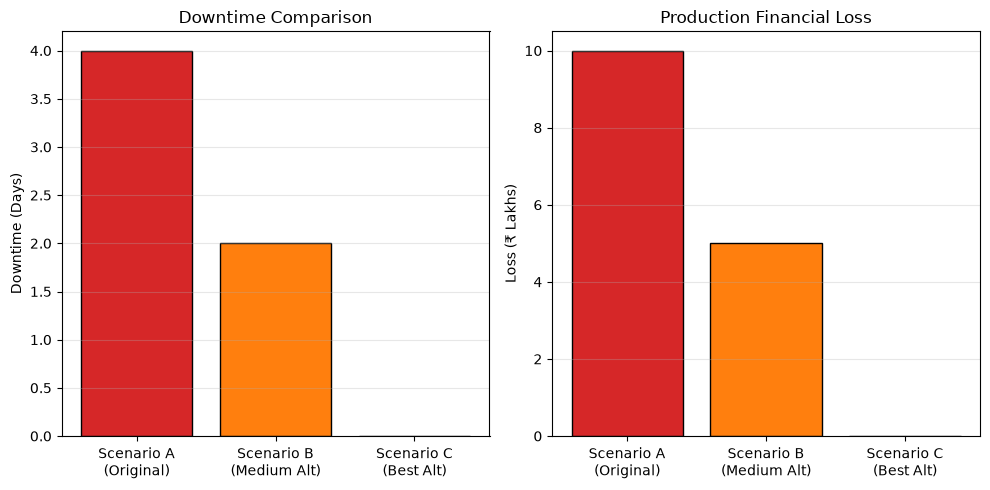

In [11]:
# Compare Scenario A (Original), Scenario B (Average Alt), Scenario C (Best Alt)
best_alt = test_results.iloc[0]

stock_cov = 100.0 / 50.0
downtime_orig = max(0.0, 6.0 - stock_cov)
loss_orig = downtime_orig * 50.0 * 5000.0

downtime_best = max(0.0, downtime_orig - best_alt["Downtime_Prevented_Days"])
loss_best = downtime_best * 50.0 * 5000.0

scenario_comparison = pd.DataFrame([
    {
        "Scenario": "Scenario A: Original Supplier Only",
        "Lead_Time / Arrival": "Delayed by 6.0 Days (Arrival: Day 14)",
        "Downtime_Days": downtime_orig,
        "Production_Loss_INR": loss_orig,
        "Net_Financial_Impact": -loss_orig
    },
    {
        "Scenario": "Scenario B: Alternative (Lead Time: 4 Days)",
        "Lead_Time / Arrival": "Arrives Day 4",
        "Downtime_Days": max(0.0, 4.0 - stock_cov),
        "Production_Loss_INR": max(0.0, 4.0 - stock_cov) * 50.0 * 5000.0,
        "Net_Financial_Impact": -(max(0.0, 4.0 - stock_cov) * 50.0 * 5000.0)
    },
    {
        "Scenario": f"Scenario C: Best Alternative ({best_alt['Supplier_ID']})",
        "Lead_Time / Arrival": f"Arrives in {best_alt['Lead_Time_Days']} Days",
        "Downtime_Days": downtime_best,
        "Production_Loss_INR": loss_best,
        "Net_Financial_Impact": best_alt["Net_Benefit_INR"]
    }
])

display(scenario_comparison)

# Visualize 3 scenarios
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.bar(
    ["Scenario A\n(Original)", "Scenario B\n(Medium Alt)", "Scenario C\n(Best Alt)"],
    scenario_comparison["Downtime_Days"],
    color=["#d62728", "#ff7f0e", "#2ca02c"],
    edgecolor="black"
)
plt.ylabel("Downtime (Days)")
plt.title("Downtime Comparison")
plt.grid(axis='y', alpha=0.3)

plt.subplot(1, 2, 2)
plt.bar(
    ["Scenario A\n(Original)", "Scenario B\n(Medium Alt)", "Scenario C\n(Best Alt)"],
    scenario_comparison["Production_Loss_INR"] / 100000.0,
    color=["#d62728", "#ff7f0e", "#2ca02c"],
    edgecolor="black"
)
plt.ylabel("Loss (₹ Lakhs)")
plt.title("Production Financial Loss")
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


### 12. Save Trained Alternative Supplier Engine

In [12]:
ENGINE_PATH = Path("../models/alternative_supplier_engine.pkl")

engine_artifact = {
    "model_pipeline": alt_model_pipe,
    "candidate_db": candidate_db,
    "feature_columns": feature_cols
}

joblib.dump(engine_artifact, ENGINE_PATH)
print(f"Alternative supplier recommendation engine successfully saved to: {ENGINE_PATH.resolve()}")
print(f"File size: {os.path.getsize(ENGINE_PATH):,} bytes")


Alternative supplier recommendation engine successfully saved to: C:\Users\SRS1\OneDrive - SRS ConsultingInc\Documents\ML Main\models\alternative_supplier_engine.pkl
File size: 5,010,747 bytes
